# Chapitre 1 - Cours 4 : fiabilité et tolérance aux fautes

Un système fiable continue de fonctionner correctement **même quand quelque chose se
passe mal**. Ce notebook précise ce qui peut mal se passer (matériel, logiciel, humains)
et quantifie les parades : redondance, indépendance des pannes, injection de fautes,
déploiements progressifs. Il couvre la section *Reliability* (*Hardware Faults*, *Software Errors*, *Human Errors*, *How Important Is Reliability?*).

**Plan.**

1. Fautes, défaillances et points de défaillance uniques.
2. Tolérer une faute, et le vérifier en injectant des fautes.
3. Les pannes matérielles : des événements rares qui deviennent quotidiens.
4. Redondance et pannes corrélées.
5. Les fautes logicielles, corrélées par nature.
6. Les erreurs humaines et les déploiements progressifs.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import requirements as rq
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## 1. Fautes, défaillances et points de défaillance uniques (section *Reliability*)

Pour un logiciel, « fonctionner correctement » recouvre plusieurs attentes : rendre le
service attendu, tolérer les erreurs et les usages imprévus des utilisateurs, offrir des
performances suffisantes sous la charge prévue, empêcher les accès non autorisés. Être
fiable, c'est continuer à le faire **quand les choses tournent mal**. Le livre distingue
deux niveaux :

- une **faute** (fault) : un composant cesse de fonctionner correctement (un disque, une
  machine, un service externe) ;
- une **défaillance** (failure) : le système **dans son ensemble** cesse de rendre le
  service attendu.

C'est le même phénomène vu à deux échelles : la panne d'un disque est une défaillance
du disque, mais seulement une faute pour un système qui garde une copie des données
ailleurs. Un système est **tolérant aux fautes** s'il continue à rendre le service
malgré certaines fautes ; un composant dont la faute entraîne la défaillance de tout le
système est un **point de défaillance unique** (SPOF, single point of failure).

**Quantifier.** Si les composants tombent en panne indépendamment, la disponibilité
d'une chaîne de composants **tous nécessaires** est le produit de leurs disponibilités ;
celle de composants **redondants** (un seul suffit) vaut $1 - \prod (1 - a_i)$.
Comparons trois architectures d'une application web.

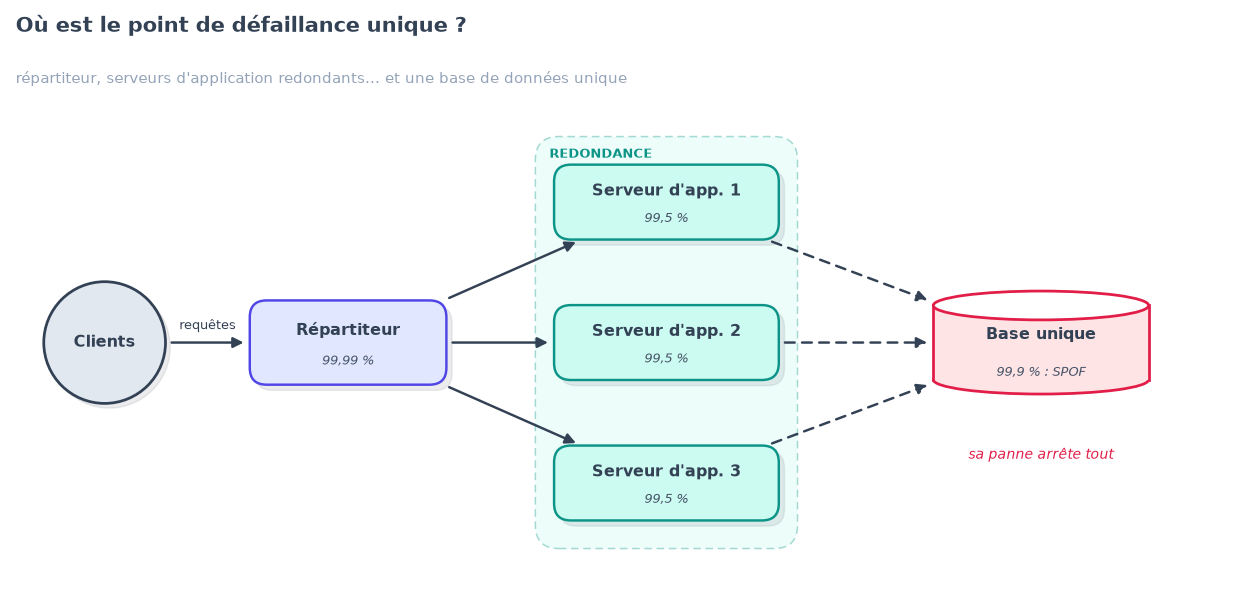

In [2]:
d = Diagram(13, 5.2, title="Où est le point de défaillance unique ?",
            subtitle="répartiteur, serveurs d'application redondants... et une base de données unique")
d.box("u", 1.0, 2.6, "Clients", kind="user", w=1.3, color=SLATE)
d.box("lb", 3.6, 2.6, "Répartiteur", sub="99,99 %", color=INDIGO, w=2.1)
d.box("db", 11.0, 2.6, "Base unique", sub="99,9 % : SPOF", color=ROSE, kind="db", w=2.3, h=1.1)
for i, y in enumerate([4.1, 2.6, 1.1]):
    d.box(f"a{i}", 7.0, y, f"Serveur d'app. {i + 1}", sub="99,5 %", color=TEAL, w=2.4, h=0.8)
    d.arrow("lb", f"a{i}")
    d.arrow(f"a{i}", "db", style="dashed")
d.arrow("u", "lb", "requêtes")
d.group(5.6, 0.4, 8.4, 4.8, "redondance", color=TEAL)
d.note(11.0, 1.4, "sa panne arrête tout", color=ROSE)
d.show()

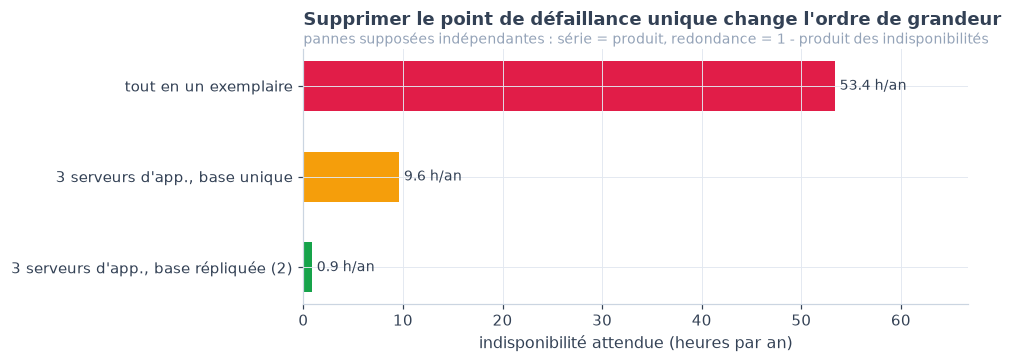

,disponibilité,neuf,indisponibilité par an (h)
tout en un exemplaire,0.9939,2.2151,53.3869
"3 serveurs d'app., base unique",0.9989,2.9586,9.6362
"3 serveurs d'app., base répliquée (2)",0.9999,3.9951,0.8859


In [3]:
a_lb, a_app, a_db = 0.9999, 0.995, 0.999
archis = {
    "tout en un exemplaire": rq.series_availability(a_lb, a_app, a_db),
    "3 serveurs d'app., base unique": rq.series_availability(a_lb, rq.parallel_availability(a_app, a_app, a_app), a_db),
    "3 serveurs d'app., base répliquée (2)": rq.series_availability(a_lb, rq.parallel_availability(a_app, a_app, a_app),
                                                                    rq.parallel_availability(a_db, a_db)),
}
A = pd.DataFrame({"disponibilité": archis}).assign(
    neuf=lambda df: df["disponibilité"].map(rq.nines),
    **{"indisponibilité par an (h)": lambda df: df["disponibilité"].map(lambda a: rq.downtime_minutes(a) / 60)})
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(A.index[::-1], A["indisponibilité par an (h)"].values[::-1], color=[GREEN, AMBER, ROSE], height=0.55)
annotate_bars(ax, "{:.1f} h/an")
ax.set_xlabel("indisponibilité attendue (heures par an)")
ax.set_xlim(0, A["indisponibilité par an (h)"].max() * 1.25)
ax.set_title("Supprimer le point de défaillance unique change l'ordre de grandeur")
subtitle(ax, "pannes supposées indépendantes : série = produit, redondance = 1 - produit des indisponibilités")
plt.tight_layout(); plt.show()
A

Tripler les serveurs d'application ne suffit pas : la base unique (8,8 h de panne par
an) domine. En la répliquant, l'indisponibilité tombe à moins d'une heure par an... à
condition que les pannes soient **indépendantes**, hypothèse qui sera mise à mal en
sections 4 et 5. La tolérance aux fautes est d'ailleurs toujours **limitée** à un certain
nombre de certains types de fautes : un système qui fonctionne tant qu'au moins $k$ de
ses $n$ répliques sont en vie (un quorum, chapitre 5) a pour
disponibilité $\sum_{i \ge k} \binom{n}{i} a^i (1-a)^{n-i}$.

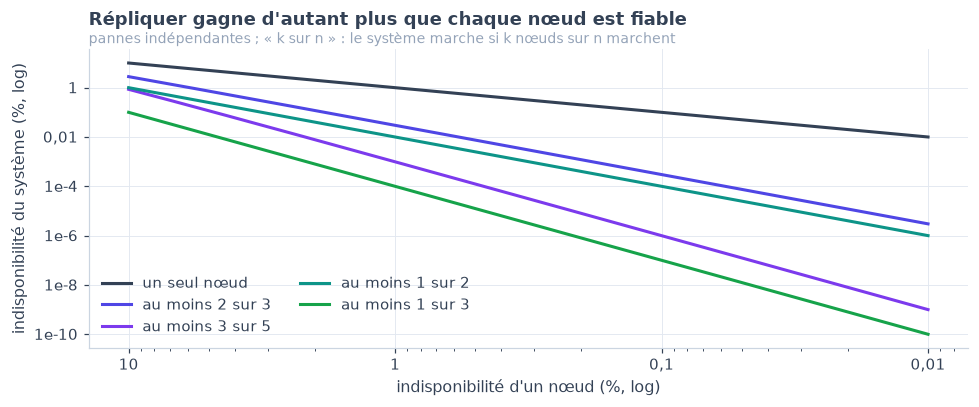

In [4]:
a_ = np.linspace(0.9, 0.9999, 300)
fig, ax = plt.subplots(figsize=(9, 3.8))
for (k, n), c in zip([(1, 1), (2, 3), (3, 5), (1, 2), (1, 3)], [SLATE, INDIGO, VIOLET, TEAL, GREEN]):
    ax.plot((1 - a_) * 100, [(1 - rq.k_of_n_availability(x, k, n)) * 100 for x in a_], color=c,
            label=f"au moins {k} sur {n}" if n > 1 else "un seul nœud")
ax.set_xscale("log"); ax.set_yscale("log"); rq.plain_log_axis(ax)
ax.invert_xaxis()
ax.set_xlabel("indisponibilité d'un nœud (%, log)"); ax.set_ylabel("indisponibilité du système (%, log)")
ax.set_title("Répliquer gagne d'autant plus que chaque nœud est fiable")
subtitle(ax, "pannes indépendantes ; « k sur n » : le système marche si k nœuds sur n marchent")
ax.legend(loc="lower left", ncol=2)
plt.tight_layout(); plt.show()

Sur ce graphique log-log, la pente de chaque courbe est le nombre de pannes **simultanées**
nécessaires pour arrêter le système : 1 pour un nœud seul, 2 pour « 2 sur 3 » ou
« 1 sur 2 », 3 pour « 3 sur 5 » ou « 1 sur 3 ». Diviser par 10 l'indisponibilité d'un
nœud la divise par 100 ou 1 000 pour le système.

### Quelle importance accorder à la fiabilité ? (encadré *How Important Is Reliability?*)

La fiabilité ne concerne pas que les centrales nucléaires : un bogue dans une
application de gestion fait perdre de la productivité (et expose à des risques
juridiques si des chiffres faux sont publiés), une panne de site marchand coûte du
chiffre d'affaires et de la réputation. Une panne de quelques minutes est souvent
tolérable ; une **perte ou une corruption définitive de données** ne l'est presque
jamais (pensez aux photos de famille confiées à une application). On peut choisir de
sacrifier de la fiabilité pour réduire les coûts, pour un prototype par exemple, mais en
connaissance de cause.

> **À retenir.** Une faute touche un composant, une défaillance touche le service. On
> rend un système tolérant aux fautes en supprimant ses points de défaillance uniques :
> en série les disponibilités se multiplient, en redondance les indisponibilités se
> multiplient, tant que les pannes sont indépendantes.

## 2. Tolérer une faute, et le vérifier en injectant des fautes (section *Reliability*)

Reprenons le fan-out du cours 1 : des **travailleurs** insèrent chaque message dans les
timelines des abonnés. Que se passe-t-il si un travailleur tombe en panne au milieu d'une
tâche ? Pour être tolérant, il faut qu'un autre travailleur reprenne la tâche **sans
perdre** de livraison **ni en dupliquer**. Trois implémentations (classes
`rq.FanoutCoordinator`, `rq.FanoutWorker`, `rq.TimelineStore`, sur le simulateur
`ddia.sim`) :

- **naïve** : le coordinateur confie chaque tâche une fois pour toutes ;
- **avec relance** : si une tâche n'est pas acquittée après 4 unités de temps, le
  coordinateur la confie à l'autre travailleur, qui la recommence depuis le début ;
- **idempotente** : relance, et le stockage ignore une insertion déjà reçue (clé
  message + abonné).

Rejouons la variante « avec relance » avec un travailleur `w1` qui tombe en panne à
t = 0,9 (et redémarre 3 unités plus tard), sur 2 messages de 3 abonnés.

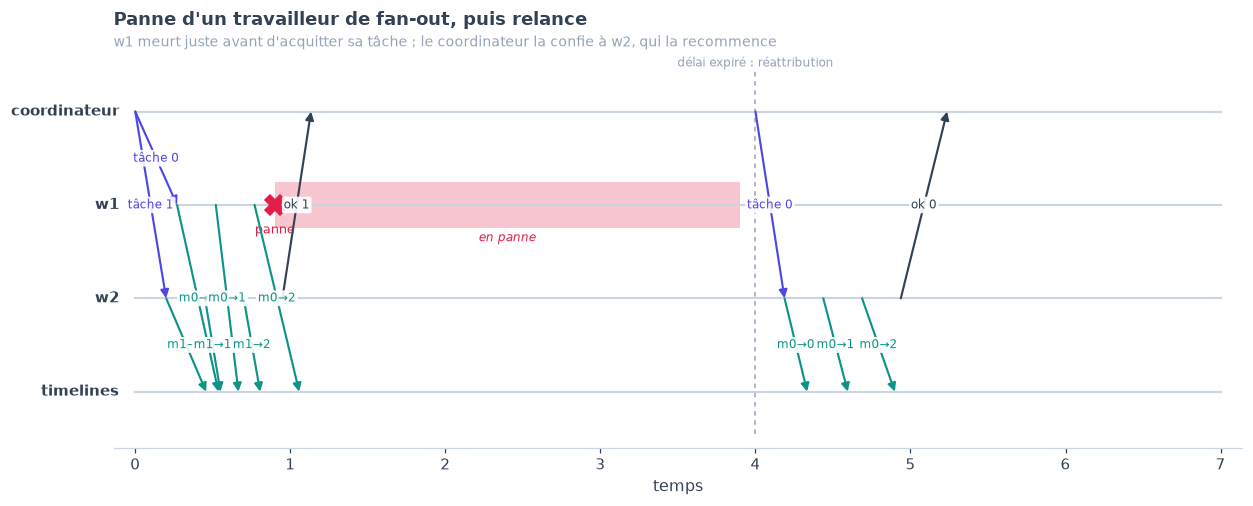

insertions reçues : ['m1→0', 'm0→0', 'm1→1', 'm0→1', 'm1→2', 'm0→2', 'm0→0', 'm0→1', 'm0→2']
verdict : {'perdues': 0, 'dupliquees': 3}


In [5]:
net, store, verdict = rq.fanout_fault_run("relance", crash_at=0.9, n_posts=2, n_followers=3, seed=1, until=12)
st = SpaceTime(["coordinateur", "w1", "w2", "timelines"], t_max=7, width=11.5,
               title="Panne d'un travailleur de fan-out, puis relance",
               subtitle="w1 meurt juste avant d'acquitter sa tâche ; le coordinateur la confie à w2, qui la recommence")
colors = {"task": INDIGO, "insert": TEAL, "done": SLATE}
def label(dlv):
    m = dlv.msg
    if m[0] == "task":
        return f"tâche {m[1]}"
    if m[0] == "insert":
        return f"m{m[1] - 100}→{m[2] % 1000}"
    return f"ok {m[1]}"
st.from_trace([x for x in net.trace if x.t_send < 7], color_of=lambda x: colors[x.msg[0]], label_of=label)
st.event("w1", 0.9, "panne", kind="crash")
st.span("w1", 0.9, 3.9, "en panne", color=ROSE)
st.vline(4.0, "délai expiré : réattribution")
st.show()
print("insertions reçues :", [f"m{p - 100}→{f % 1000}" for p, f in store.rows])
print("verdict :", verdict)

La tâche 0 confiée à `w1` a livré ses trois insertions, mais `w1` est tombé juste avant
d'envoyer son acquittement. Le coordinateur ne peut pas distinguer ce cas d'une panne au
début de la tâche : sans acquittement au bout du délai, il la confie à `w2`, qui la
reprend **depuis le début**. Les trois insertions sont livrées une seconde fois. Rien
n'est perdu, mais chaque abonné voit le message en double. Pour obtenir l'effet « exactement une fois » (exactly-once,
chapitre 11), il faut que l'opération répétée soit **idempotente**.

**Injecter des fautes pour trouver les bogues.** Le livre fait une remarque
contre-intuitive : dans un système tolérant aux fautes, il est sage d'**augmenter** le
taux de fautes en les provoquant délibérément (tuer des processus au hasard, comme le fait le Chaos Monkey de Netflix).
Beaucoup de bogues critiques se cachent dans la gestion des erreurs, rarement exercée ;
l'injection de fautes la teste en continu.
Faisons-le : 300 exécutions, chacune avec une panne d'un travailleur tiré au hasard à un
instant aléatoire, et vérifions l'invariant « chaque (message, abonné) livré exactement
une fois ».

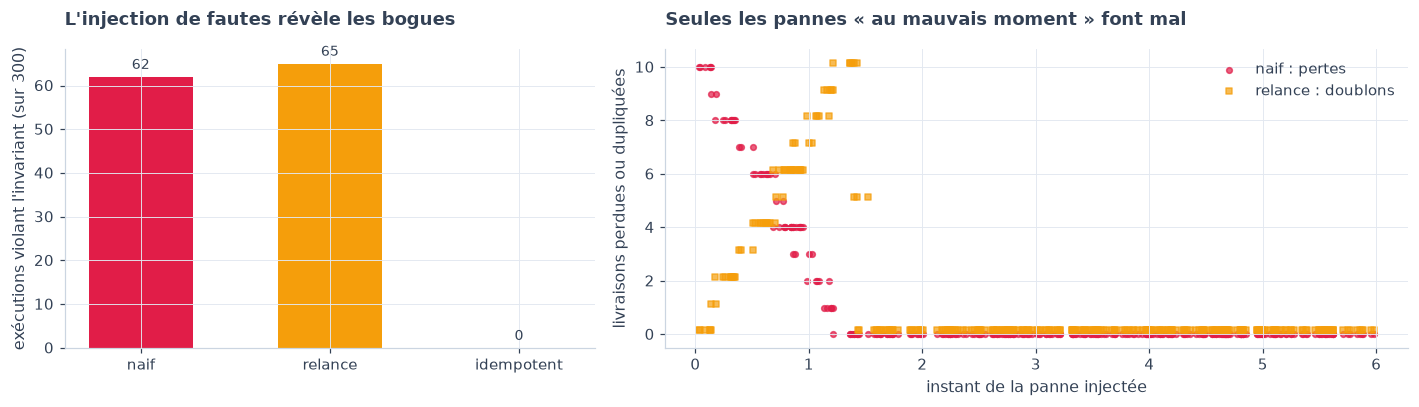

,essais_en_echec,perdues,dupliquees
variante,,,
naif,62,332,0
relance,65,0,363
idempotent,0,0,0


In [6]:
rows = []
g = np.random.default_rng(42)
for k in range(300):
    t_c, node = float(g.uniform(0, 6)), str(g.choice(["w1", "w2"]))
    for v in ["naif", "relance", "idempotent"]:
        _, _, ver = rq.fanout_fault_run(v, crash_at=t_c, crash_node=node, seed=k)
        rows.append(dict(essai=k, variante=v, t_panne=t_c, **ver))
F = pd.DataFrame(rows)
resume = F.groupby("variante").agg(essais_en_echec=("perdues", lambda s: 0), perdues=("perdues", "sum"),
                                   dupliquees=("dupliquees", "sum"))
resume["essais_en_echec"] = F.assign(ko=(F.perdues > 0) | (F.dupliquees > 0)).groupby("variante").ko.sum()
resume = resume.loc[["naif", "relance", "idempotent"]]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1, 1.4]))
ax.bar(resume.index, resume.essais_en_echec, color=[ROSE, AMBER, GREEN], width=0.55)
annotate_bars(ax, "{:.0f}")
ax.set_ylabel("exécutions violant l'invariant (sur 300)")
ax.set_title("L'injection de fautes révèle les bogues")
for v, c, mk in [("naif", ROSE, "o"), ("relance", AMBER, "s")]:
    sub = F[F.variante == v]
    ax2.scatter(sub.t_panne, sub.perdues + sub.dupliquees + (0.15 if v == "relance" else 0), s=14, color=c,
                marker=mk, alpha=0.7, label=f"{v} : {'pertes' if v == 'naif' else 'doublons'}")
ax2.set_xlabel("instant de la panne injectée"); ax2.set_ylabel("livraisons perdues ou dupliquées")
ax2.set_title("Seules les pannes « au mauvais moment » font mal")
ax2.legend(loc="upper right")
plt.tight_layout(); plt.show()
resume

La variante naïve perd des livraisons, la variante avec relance en duplique, et seule la
variante idempotente passe les 300 essais. Notez que dans une bonne partie des essais,
même la variante naïve s'en sort : la panne survient après la fin du travail. C'est
exactement pourquoi ces bogues survivent aux tests habituels et pourquoi il faut les
provoquer **systématiquement** et **au hasard**.

On préfère en général **tolérer** les fautes plutôt que les **empêcher**, sauf quand il
n'existe pas de remède : une fuite de données confidentielles, par exemple, ne se répare
pas. La sécurité relève donc de la prévention, et sort du périmètre du livre.

> **À retenir.** Tolérer la panne d'un travailleur demande une **détection** (délai
> d'acquittement), une **reprise** par un autre, et des opérations **idempotentes** pour
> que la reprise ne duplique rien. L'injection de fautes aléatoires est la façon la plus
> sûre de vérifier que ce mécanisme fonctionne.

## 3. Les pannes matérielles (section *Hardware Faults*)

On mesure la fiabilité d'un composant par son **taux annuel de panne** (AFR, annualized
failure rate) ou son **temps moyen avant panne** (MTTF, mean time to failure). Pour un
taux de panne constant $\lambda$, la durée de vie suit une loi exponentielle :
$\text{MTTF} = 1/\lambda$ et $\text{AFR} = 1 - e^{-8760/\text{MTTF}}$ (MTTF en heures).
Le livre cite un MTTF de 10 à 50 ans pour les disques durs, soit un AFR de 2 à 10 %.

Un MTTF de plusieurs décennies semble rassurant. Mais dans un parc de 10 000 disques à
3 % par an, on attend $10\,000 \times 0{,}03 / 365 \approx 0{,}8$ panne **par jour** : à
grande échelle, la panne matérielle n'est plus un accident, c'est la routine. Le nombre
de pannes un jour donné suit une loi de Poisson ; simulons un an de ce parc.

MTTF = 32.8 ans ; pannes attendues par jour = 0.83


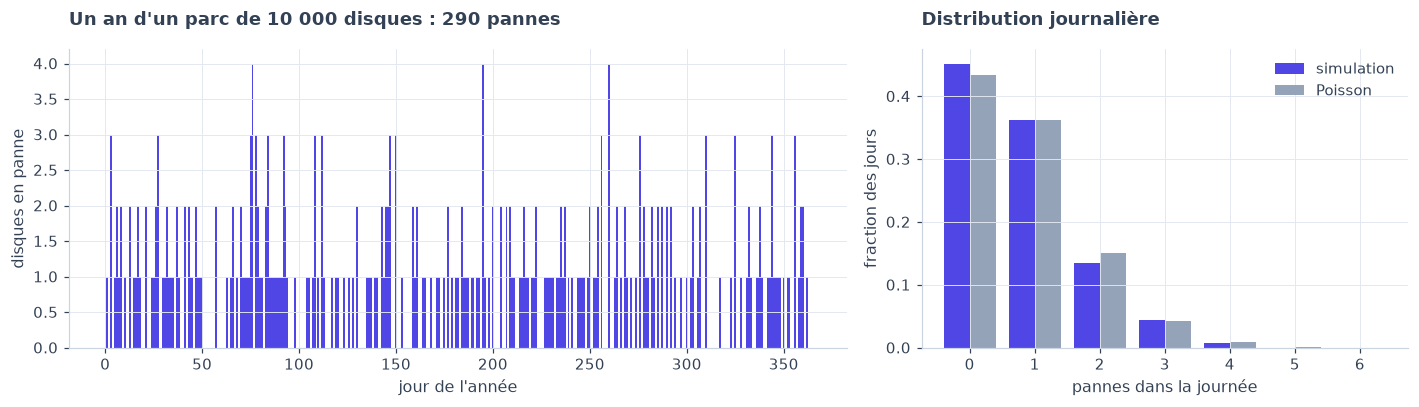

In [7]:
n_disques, afr = 10_000, 0.03
print(f"MTTF = {rq.mttf_hours_from_afr(afr) / 8760:.1f} ans ; pannes attendues par jour = "
      f"{rq.expected_failures(n_disques, afr, 1):.2f}")
lam_h = 1 / rq.mttf_hours_from_afr(afr)
vies = rng.exponential(1 / lam_h, n_disques)                 # heures, un remplacement par panne
pannes = []
for i in range(n_disques):
    t = vies[i]
    while t < 8760:
        pannes.append(t)
        t += rng.exponential(1 / lam_h)
par_jour = np.bincount((np.array(pannes) // 24).astype(int), minlength=365)[:365]

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
ax.bar(np.arange(365), par_jour, color=INDIGO, width=1.0)
ax.set_xlabel("jour de l'année"); ax.set_ylabel("disques en panne")
ax.set_title(f"Un an d'un parc de {n_disques:,} disques : {len(pannes)} pannes".replace(",", " "))
k = np.arange(0, 7)
obs = np.bincount(par_jour, minlength=7)[:7] / 365
ax2.bar(k - 0.2, obs, width=0.4, color=INDIGO, label="simulation")
ax2.bar(k + 0.2, rq.poisson_pmf(k, rq.expected_failures(n_disques, afr, 1)), width=0.4, color=GRAY, label="Poisson")
ax2.set_xlabel("pannes dans la journée"); ax2.set_ylabel("fraction des jours")
ax2.set_title("Distribution journalière")
ax2.legend()
plt.tight_layout(); plt.show()

Environ 300 pannes dans l'année, et moins d'un jour sur deux sans aucune. Le
remplacement d'un disque défectueux doit donc être une **opération courante**, et le
logiciel doit continuer à fonctionner pendant ce temps.

> **À retenir.** Un composant fiable (MTTF de plusieurs décennies) devient une source de
> pannes quotidiennes à l'échelle d'un parc : nombre de pannes ≈ taille du parc × AFR.
> À grande échelle, les pannes matérielles font partie du fonctionnement normal.

## 4. Redondance et pannes corrélées (section *Hardware Faults*)

La première réponse est la **redondance** : disques en RAID, alimentations doubles,
batteries et groupes électrogènes. Pour des données répliquées en $r$ copies sur $r$
disques, on ne perd des données que si toutes les copies tombent avant d'avoir été
reconstruites. Avec un taux de panne $\lambda$ par disque et un temps de reconstruction
$T$ (court devant le MTTF), on perd des données quand les $r$ copies sont en panne **en
même temps** : après une première panne (taux $r\lambda$, n'importe laquelle des $r$
copies), chacune des $r-1$ autres doit tomber dans la fenêtre de durée $T$ qui suit
(probabilité $\approx \lambda T$ chacune). Le taux de perte vaut donc
$r\,\lambda^r T^{r-1}$, d'où la **durée moyenne avant perte de données** (MTTDL) :
$$\text{MTTDL} \approx \frac{1}{r\,\lambda^r\,T^{r-1}}, \qquad \text{pour } r = 2 :\ \frac{\text{MTTF}^2}{2\,T}.$$

Validons la formule par simulation (`rq.simulate_data_loss`), avec des paramètres
exagérés pour voir des pertes en un temps raisonnable : AFR de 40 %, reconstruction
d'une semaine, 10 ans, 30 000 groupes.

In [8]:
rows = []
for r in [1, 2, 3]:
    t_loss = rq.simulate_data_loss(r, afr=0.40, rebuild_hours=168, years=10, n_groups=30_000, seed=r)
    p_sim = np.isfinite(t_loss).mean()
    p_theo = 1 - math.exp(-10 * 8760 / rq.mttdl_hours(0.40, r, 168))
    rows.append(dict(copies=r, p_perte_10ans_sim=p_sim, p_perte_10ans_formule=p_theo))
pd.DataFrame(rows)

,copies,p_perte_10ans_sim,p_perte_10ans_formule
0,1,0.9942,0.9940
1,2,0.0906,0.0952
2,3,0.0009,0.0015


La formule et la simulation concordent à quelques dizaines de pourcents près, ce qui est
remarquable pour une approximation aussi simple (elle surestime légèrement le risque,
car elle compte comme indépendants des événements qui se recouvrent ; avec $\lambda T$
proche de 1 %, l'écart reste modeste). Avec des valeurs réalistes (AFR 3 %, reconstruction en 24 h), chaque copie
supplémentaire divise le risque par un facteur énorme, de l'ordre de
$1/(\lambda T) \approx 10^4$.

**Mais les pannes sont-elles indépendantes ?** L'expérience montre de fortes
**corrélations** : disques du même lot de fabrication, même rack (alimentation,
température, commutateur réseau), même centre de données. Modélisons-les par un **choc
commun** qui détruit toutes les copies d'un groupe d'un coup, à un taux très faible : une
fois par millénaire et par groupe ($10^{-3}$ par an).

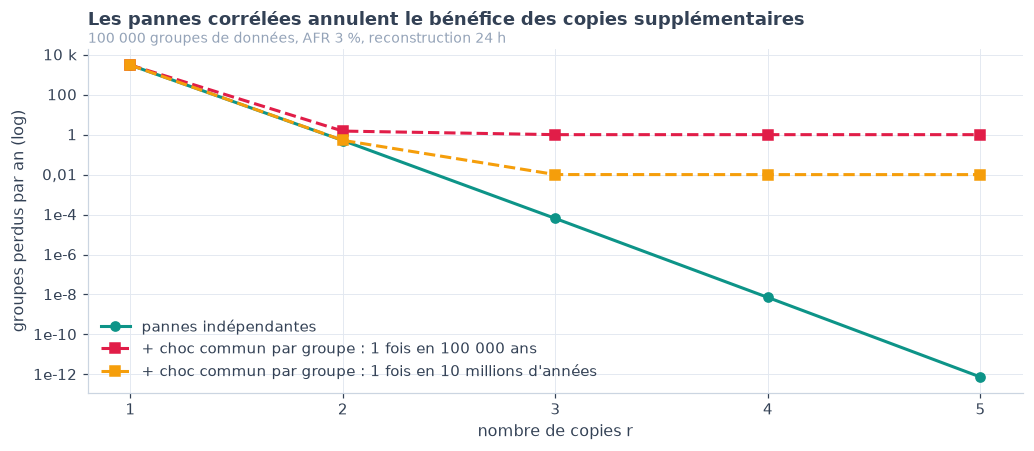

In [9]:
rs = np.arange(1, 6)
groupes = 100_000
indep = np.array([groupes * 8760 / rq.mttdl_hours(0.03, int(r), 24) for r in rs])   # groupes perdus par an
fig, ax = plt.subplots(figsize=(9.5, 4.2))
ax.semilogy(rs, indep, "o-", color=TEAL, label="pannes indépendantes")
for choc, c, nom in [(1e-5, ROSE, "1 fois en 100 000 ans"), (1e-7, AMBER, "1 fois en 10 millions d'années")]:
    ax.semilogy(rs, indep + choc * groupes, "s--", color=c, label=f"+ choc commun par groupe : {nom}")
rq.plain_log_axis(ax, "y")
ax.set_xticks(rs); ax.set_xlabel("nombre de copies r"); ax.set_ylabel("groupes perdus par an (log)")
ax.set_title("Les pannes corrélées annulent le bénéfice des copies supplémentaires")
subtitle(ax, "100 000 groupes de données, AFR 3 %, reconstruction 24 h")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

Avec des pannes indépendantes, chaque copie divise les pertes par un facteur de l'ordre
de $1/(\lambda T) \approx 10^4$ : avec trois copies, on perd un groupe tous les dix mille
ans environ sur 100 000 groupes. Mais dès qu'un choc commun existe, même
extrêmement rare, les pertes **plafonnent** à son niveau, quel que soit le nombre de
copies : la 4e et la 5e copie ne servent à rien si elles sont dans le même rack. D'où la règle : placer les copies dans
des **domaines de panne différents** (racks, alimentations, centres de données) pour
les rendre aussi indépendantes que possible.

**La redondance logicielle et les mises à jour progressives.** Les grands systèmes
tolèrent la perte de machines **entières** au niveau logiciel, ce qui a un autre
avantage : on peut redémarrer les nœuds **un par un** (pour appliquer un correctif de
sécurité du système d'exploitation, par exemple) sans interrompre le service. C'est la
**mise à jour progressive** (rolling upgrade, chapitre 4).

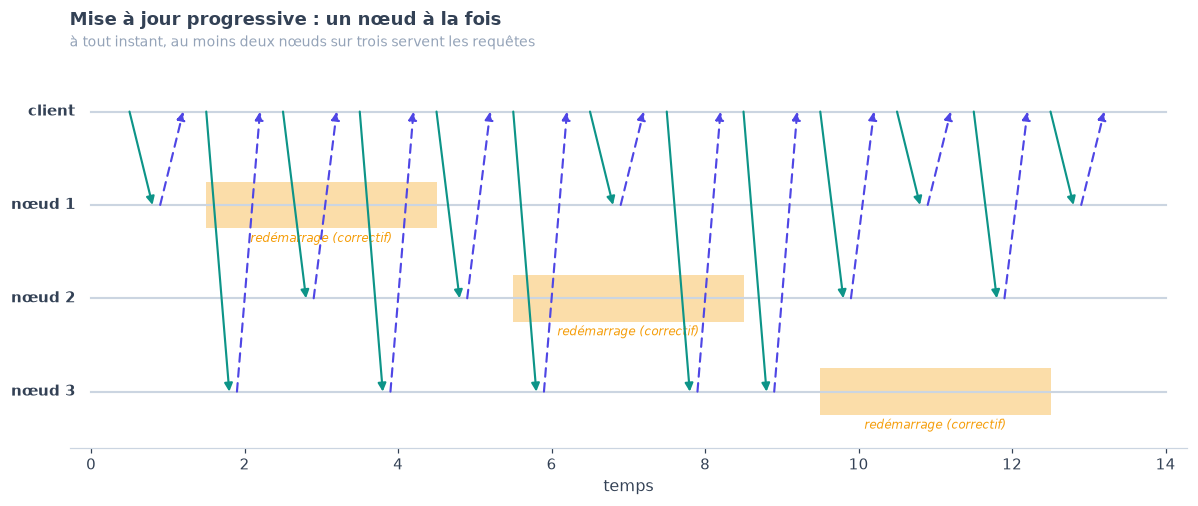

In [10]:
st = SpaceTime(["client", "nœud 1", "nœud 2", "nœud 3"], t_max=14, width=11,
               title="Mise à jour progressive : un nœud à la fois",
               subtitle="à tout instant, au moins deux nœuds sur trois servent les requêtes")
for i, (t0, t1) in enumerate([(1.5, 4.5), (5.5, 8.5), (9.5, 12.5)]):
    st.span(f"nœud {i + 1}", t0, t1, "redémarrage (correctif)", color=AMBER, alpha=0.35)
for k, t in enumerate(np.arange(0.5, 13.5, 1.0)):
    en_maj = [i for i, (t0, t1) in enumerate([(1.5, 4.5), (5.5, 8.5), (9.5, 12.5)]) if t0 <= t + 0.3 <= t1]
    cible = [i for i in range(3) if i not in en_maj][k % (3 - len(en_maj))]
    st.msg("client", t, f"nœud {cible + 1}", t + 0.3, "", color=TEAL)
    st.msg(f"nœud {cible + 1}", t + 0.4, "client", t + 0.7, "", color=INDIGO, style="dashed")
st.show()

> **À retenir.** La redondance réduit le risque de façon spectaculaire, **si les pannes
> sont indépendantes** : MTTDL ≈ $1/(r\,\lambda^r T^{r-1})$. Les pannes corrélées
> (même rack, même lot) plafonnent le bénéfice : on répartit les copies sur des domaines
> de panne distincts. Tolérer la perte d'une machine permet aussi les mises à jour
> progressives sans interruption.

## 5. Les fautes logicielles, corrélées par nature (section *Software Errors*)

Les pannes matérielles sont surtout indépendantes. Les fautes logicielles, elles, sont
souvent **fortement corrélées** : tous les nœuds exécutent le même code, donc ont les
mêmes bogues. Exemples du livre : la seconde intercalaire du 30 juin 2012, qui a fait se
bloquer simultanément de nombreuses applications Java à cause d'un bogue du noyau
Linux ;
un processus incontrôlé qui épuise une ressource partagée ; un service dont on dépend qui
ralentit ou renvoie des réponses corrompues ; des **défaillances en cascade**.

Comparons deux mondes pour un parc de 100 nœuds observé pendant une heure : pannes
matérielles indépendantes (chaque nœud tombe avec probabilité 1 %), ou bogue logiciel
commun (avec probabilité 0,1 %, une condition rare déclenche le même bogue sur
**tous** les nœuds).

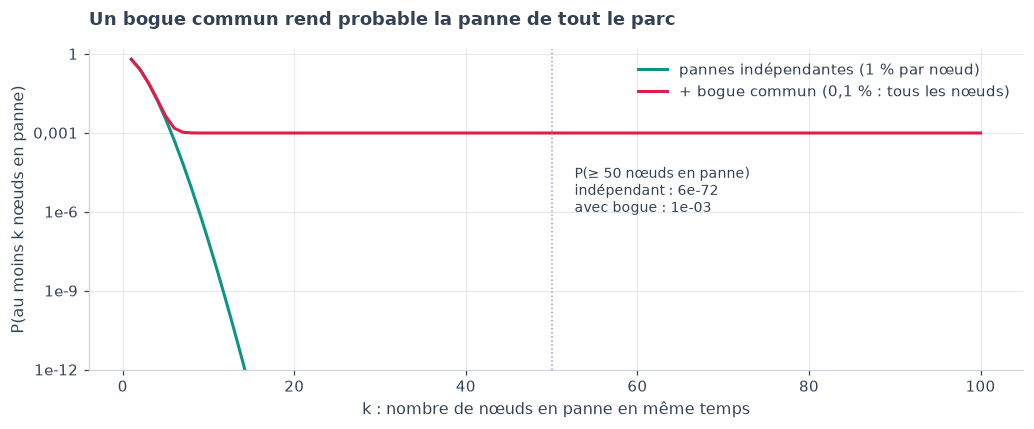

In [11]:
from math import comb
n_noeuds, p_ind, p_bug = 100, 0.01, 0.001
ks = np.arange(0, n_noeuds + 1)
p_k_ind = np.array([comb(n_noeuds, int(k)) * p_ind ** k * (1 - p_ind) ** (n_noeuds - k) for k in ks])
surv_ind = np.cumsum(p_k_ind[::-1])[::-1]                         # P(au moins k en panne)
surv_bug = (1 - p_bug) * surv_ind + p_bug * 1.0                  # avec le bogue, tous tombent
fig, ax = plt.subplots(figsize=(9.5, 4))
ax.semilogy(ks[1:], np.maximum(surv_ind[1:], 1e-300), color=TEAL, label="pannes indépendantes (1 % par nœud)")
ax.semilogy(ks[1:], surv_bug[1:], color=ROSE, label="+ bogue commun (0,1 % : tous les nœuds)")
ax.set_ylim(1e-12, 1.5)
ax.set_yticks([1e-12, 1e-9, 1e-6, 1e-3, 1]); ax.set_yticklabels(["1e-12", "1e-9", "1e-6", "0,001", "1"])
ax.axvline(50, color=GRAY, ls=":", lw=1)
ax.annotate(f"P(≥ 50 nœuds en panne)\nindépendant : {surv_ind[50]:.0e}\navec bogue : {surv_bug[50]:.0e}",
            (50, 1e-6), (15, 0), textcoords="offset points", fontsize=9, color=SLATE)
ax.set_xlabel("k : nombre de nœuds en panne en même temps"); ax.set_ylabel("P(au moins k nœuds en panne)")
ax.set_title("Un bogue commun rend probable la panne de tout le parc")
ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

Avec des pannes indépendantes, perdre la moitié du parc d'un coup est d'une
improbabilité astronomique. Un seul bogue commun, même rare, rend cet événement des
dizaines d'ordres de grandeur plus probable que ce qu'annonce le modèle indépendant : la redondance
ne protège pas contre ce qui frappe toutes les copies à la fois.

**Défaillances en cascade.** Autre mécanisme de corrélation : quand un nœud tombe, sa
charge se reporte sur les autres. Si $n$ serveurs identiques sont occupés à $u$, la
perte d'un serveur porte les survivants à $u \cdot n/(n-1)$ ; au-delà de 100 %, ils
saturent (et, dans un vrai système, finissent par tomber eux aussi), et ainsi de suite.
Simulons 10 serveurs dont les capacités varient de ±10 % et qui tombent dès que leur
charge dépasse leur capacité.

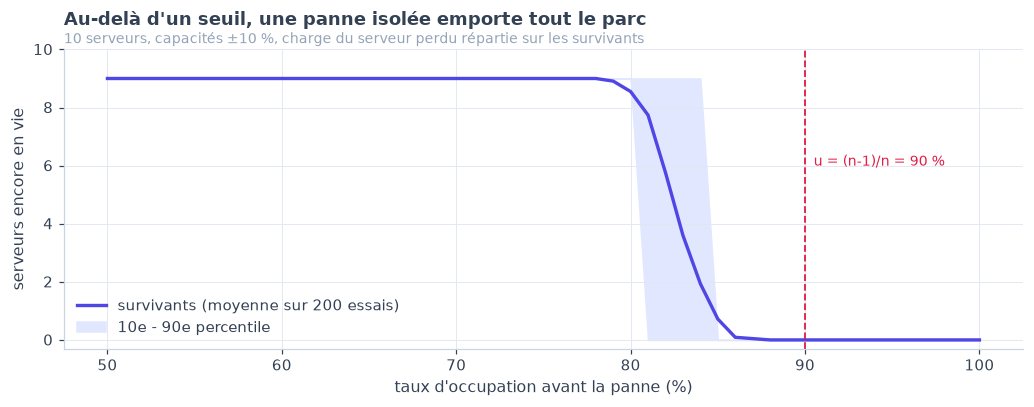

In [12]:
def cascade(u, n=10, spread=0.10, seed=0):
    g = np.random.default_rng(seed)
    cap = 1 + g.uniform(-spread, spread, n)
    total = u * cap.sum()
    alive = np.ones(n, bool)
    alive[g.integers(n)] = False                                   # panne initiale
    while True:
        load = total / alive.sum() if alive.any() else np.inf     # répartition égale
        over = alive & (load > cap)
        if not over.any() or not alive.any():
            return alive.sum()
        alive[over] = False

us = np.linspace(0.5, 1.0, 51)
surv = np.array([[cascade(u, seed=s) for s in range(200)] for u in us])
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(us * 100, surv.mean(axis=1), color=INDIGO, lw=2.2, label="survivants (moyenne sur 200 essais)")
ax.fill_between(us * 100, np.percentile(surv, 10, axis=1), np.percentile(surv, 90, axis=1), color=LIGHT[INDIGO],
                label="10e - 90e percentile")
ax.axvline(90, color=ROSE, ls="--", lw=1.2)
ax.text(90.5, 6, "u = (n-1)/n = 90 %", color=ROSE, ha="left", fontsize=9)
ax.set_xlabel("taux d'occupation avant la panne (%)"); ax.set_ylabel("serveurs encore en vie")
ax.set_ylim(-0.3, 10)
ax.set_title("Au-delà d'un seuil, une panne isolée emporte tout le parc")
subtitle(ax, "10 serveurs, capacités ±10 %, charge du serveur perdu répartie sur les survivants")
ax.legend(loc="lower left")
plt.tight_layout(); plt.show()

Jusqu'à environ 78 % d'occupation, la perte d'un serveur est absorbée (9 survivants).
Entre 80 et 86 %, la cascade devient de plus en plus probable, et au-delà la panne d'un
seul serveur emporte tout le parc, **avant** le seuil théorique $(n-1)/n = 90\,\%$ de
serveurs identiques : l'hétérogénéité avance le seuil, car les serveurs les plus faibles
cèdent les premiers et leur charge s'ajoute à celle des autres. La **marge de
capacité** est donc aussi une mesure de fiabilité.

Il n'y a pas de remède unique aux fautes logicielles systématiques, mais beaucoup de
petites choses aident : réfléchir aux hypothèses et aux interactions, tester à fond,
isoler les processus, les laisser planter et redémarrer, mesurer et surveiller le
comportement en production.

> **À retenir.** Les fautes logicielles touchent tous les nœuds à la fois (même code,
> mêmes bogues) ou se propagent (cascades) : elles échappent à la logique « redondance =
> indépendance ». On s'en protège par le test, l'isolation, la surveillance et une marge
> de capacité.

## 6. Les erreurs humaines et les déploiements progressifs (section *Human Errors*)

Les humains conçoivent, construisent et exploitent les systèmes, et ils se trompent.
Une étude citée par le livre sur de grands services internet trouve que les
**changements de configuration** faits par les opérateurs sont la première cause de
pannes, le matériel ne jouant un rôle que dans 10 à 25 % des cas.

Parmi les parades techniques : tests approfondis, **retour arrière** rapide d'une
configuration, **déploiement progressif** du nouveau code, surveillance détaillée. Le
déploiement progressif (canary) limite le **rayon d'impact** d'une erreur : on expose
d'abord 1 % des utilisateurs, puis 10 %, puis 50 %, puis tout le monde, en surveillant les
indicateurs à chaque étape. Quantifions-le par simulation : un déploiement défectueux est
détecté par la supervision au bout d'un temps aléatoire (exponentiel, de moyenne 10 min
après exposition), puis annulé en 5 minutes.

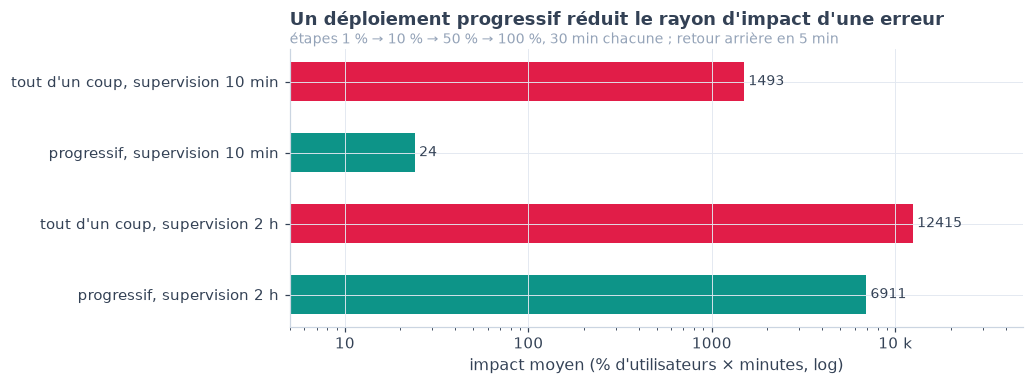

réduction de l'impact par le déploiement progressif : ×62 (supervision rapide), ×1.8 (supervision lente)


In [13]:
def impact(etapes, detect_moy, rollback=5.0, n=20_000, seed=0):
    """Utilisateurs x minutes touchés par un déploiement défectueux (moyenne sur n tirages).
    etapes : liste de (fraction exposée, durée de l'étape en minutes) ; la dernière dure
    indéfiniment."""
    g = np.random.default_rng(seed)
    t_detect = g.exponential(detect_moy, n)
    tot = np.zeros(n)
    t0 = 0.0
    for frac, duree in etapes:
        fin_etape = t0 + duree
        expo = np.clip(np.minimum(t_detect + rollback, fin_etape) - t0, 0, None)
        tot += frac * expo
        t0 = fin_etape
    return tot.mean() * 100                                     # en % d'utilisateurs x minutes

big_bang = [(1.0, np.inf)]
canary = [(0.01, 30), (0.10, 30), (0.50, 30), (1.0, np.inf)]
res = pd.Series({
    "tout d'un coup, supervision 10 min": impact(big_bang, 10),
    "progressif, supervision 10 min": impact(canary, 10),
    "tout d'un coup, supervision 2 h": impact(big_bang, 120),
    "progressif, supervision 2 h": impact(canary, 120),
})
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.barh(res.index[::-1], res.values[::-1], color=[TEAL, ROSE, TEAL, ROSE], height=0.55)
annotate_bars(ax, "{:.0f}")
ax.set_xscale("log"); rq.plain_log_axis(ax, "x")
ax.set_xlabel("impact moyen (% d'utilisateurs × minutes, log)")
ax.set_xlim(5, res.max() * 4)
ax.set_title("Un déploiement progressif réduit le rayon d'impact d'une erreur")
subtitle(ax, "étapes 1 % → 10 % → 50 % → 100 %, 30 min chacune ; retour arrière en 5 min")
plt.tight_layout(); plt.show()
print(f"réduction de l'impact par le déploiement progressif : ×{res.iloc[0] / res.iloc[1]:.0f} "
      f"(supervision rapide), ×{res.iloc[2] / res.iloc[3]:.1f} (supervision lente)")

Avec une supervision réactive, le déploiement progressif divise l'impact moyen par plus
de 50 : l'erreur est presque toujours détectée pendant l'étape à 1 %. Avec une
supervision lente, le gain fond, car l'erreur atteint souvent l'étape à 100 % avant
d'être vue. Les deux mesures se complètent : **déployer progressivement n'a de sens que
si l'on regarde** ce qui se passe à chaque étape. Le livre recommande aussi de concevoir des interfaces qui rendent « la bonne action » facile, de fournir des environnements bac à sable pour expérimenter sans risque, et de bien former les équipes.

> **À retenir.** Les erreurs humaines, surtout de configuration, sont la première cause
> de pannes. On limite leur impact par le test, le retour arrière rapide, la
> surveillance et les **déploiements progressifs**, qui réduisent le rayon d'impact à
> condition d'observer chaque étape.